# Lesson 4 — Write ACT training

You will implement the loss and update path that changes ACT weights. Earlier units used a ready policy. Here, the network and fixed training and validation batches are supplied. Lesson 3 shows how to build those batches.

Each exercise builds part of the training path. The required experiment trains ACT with a fixed seed and update budget, reloads the saved policy, and compares validation error and simulator results before and after training. Run the training cell to start it. Automated quick checks skip this experiment and report that skip.

The ACT paper uses a masked action L1 loss plus a KL penalty for its latent posterior. The KL term sums over latent values and averages over the batch. Reading: [ACT paper](https://arxiv.org/abs/2304.13705).

**PyTorch notes:** a tensor with `requires_grad=True` records operations for autograd. `backward()` fills gradients. `optimizer.step()` changes parameters. Clear gradients before each update. Call `detach()` only when you record a value for display.

Full answers are in [04-act-training-reference.ipynb](04-act-training-reference.ipynb).


# Before you code

This course assumes strong Python skills and basic machine-learning knowledge. We explain PyTorch when it first appears. Read each shape, unit, mask, and parameter definition before you run the check. The reference copy gives a complete solution; the learner copy leaves the implementation for you.

Training changes the parameters $\theta$: the tensors held by a PyTorch model. For a predicted action chunk $\hat{a}$ and a target chunk $a$, the masked L1 loss is:

$$L_{\text{action}}=\frac{\sum_{b=1}^{B}\sum_{t=1}^{T}\sum_{d=1}^{D}\left(1-m_{b,t}\right)\left|\hat{a}_{b,t,d}-a_{b,t,d}\right|}{D\sum_{b=1}^{B}\sum_{t=1}^{T}\left(1-m_{b,t}\right)}$$

Where:
* $B$ - number of examples in the batch; $b$ selects one.
* $T$ - number of action steps in a chunk; $t$ selects one.
* $D$ - number of controller values per action ($D=7$); $d$ selects one.
* $\hat{a}_{b,t,d}$ - predicted action value; $a_{b,t,d}$ - target action value.
* $m_{b,t}$ - padding mask: 1 (True) for a padded, absent target, 0 for a real target.

The mask excludes padded targets from both the sum and the denominator.

During training, ACT also encodes the target actions into a latent variable $z$. The encoder outputs a Gaussian posterior, and a KL term pulls it toward a standard normal prior. The total objective adds the two losses:

$$q(z\mid o,a)=\mathcal{N}\!\left(\mu,\ \operatorname{diag}\!\left(e^{\log\sigma^2}\right)\right), \qquad L=L_{\text{action}}+\beta L_{\text{KL}}$$

Where:
* $o$ - the observation (cameras and robot state); $a$ - the target action chunk.
* $z$ - the latent style variable, a vector of $L_z$ values.
* $\mu$, $\log\sigma^2$ - mean and log-variance vectors of the posterior, each of length $L_z$.
* $L_{\text{KL}}$ - KL divergence from $q(z\mid o,a)$ to $\mathcal{N}(0,I)$, defined in Exercise 2.
* $\beta$ - dimensionless weight of the KL term.

For one latent dimension with $\mu=1$ and $\log\sigma^2=0$, the KL term is $-\tfrac{1}{2}\left(1+0-1^2-e^{0}\right)=0.5$ nats. A batch update computes the loss, runs backpropagation to get gradients, and then calls the optimizer to change $\theta$. The supplied model keeps this lesson about the training path; later lessons build its internal pieces.


In [1]:
import os
import sys
from collections.abc import Iterable, Mapping
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn

from vla_lab.teaching.interfaces import ACTPredictionModel, LossCallback, ModelT


def find_workspace() -> Path:
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / "manifests" / "act_references.yaml").is_file():
            return candidate
    raise FileNotFoundError("Start Jupyter inside this repository.")


WORKSPACE = find_workspace()
sys.path.insert(0, str(WORKSPACE / "src"))
os.environ.setdefault("HF_HUB_CACHE", str(WORKSPACE / ".local-data/hf/hub"))
os.environ.setdefault("HF_DATASETS_CACHE", str(WORKSPACE / ".local-data/hf/datasets"))
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("HF_DATASETS_OFFLINE", "1")
os.environ.setdefault("MPLCONFIGDIR", str(WORKSPACE / ".local-data/matplotlib"))
print("Workspace:", WORKSPACE)
print("PyTorch:", torch.__version__)

Workspace: /home/michal/code/vlas_tutorial
PyTorch: 2.11.0+cu128


In [2]:
# A small deterministic fixture. It checks shapes and padding without downloading data.
B, T, D, L = 3, 4, 2, 3
fixture = {
    "action": torch.full((B, T, D), 0.5),
    "action_is_pad": torch.tensor([[0, 0, 0, 0], [0, 0, 1, 1], [0, 1, 1, 1]], dtype=torch.bool),
}


class TinyACT(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.action_value = nn.Parameter(torch.zeros(D))
        self.mu_value = nn.Parameter(torch.ones(L) * 0.1)

    def forward(
        self, batch: Mapping[str, torch.Tensor]
    ) -> tuple[torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        pred = self.action_value.view(1, 1, D).expand_as(batch["action"])
        mu = self.mu_value.unsqueeze(0).expand(batch["action"].shape[0], -1)
        return pred, (mu, torch.zeros_like(mu))

## Exercises

Implement the functions in order.

## Exercise 1 — Masked action loss

Implement `masked_action_l1(prediction, target, is_pad)`. Inputs have shapes $(B,T,D)$, $(B,T,D)$, $(B,T)$. `is_pad=True` means the timestep is padding. Return the mean absolute error across valid action values, as a scalar tensor:

$$L_{\text{action}}=\frac{\sum_{b,t,d}\left(1-m_{b,t}\right)\left|\hat{a}_{b,t,d}-a_{b,t,d}\right|}{\max\!\left(D\sum_{b,t}\left(1-m_{b,t}\right),\ 1\right)}$$

Where:
* $\hat{a}$ - `prediction`; $a$ - `target`; $m$ - `is_pad` as 0/1 values.
* $B$, $T$, $D$ - batch size, action steps, and controller values, as in "Before you code".

The $\max(\cdot,1)$ makes an all-padding batch return zero instead of dividing by zero. The mask must not give padded predictions a gradient.

**Pointers:** Expand the time mask over the action dimension. Keep the reduction as a tensor operation.

<details><summary>More hints</summary>

Invert the bool mask, add a final axis, cast to the prediction dtype, then multiply. Clamp the denominator to one.

</details>

More behaviour checks for this exercise: `check_masked_action_l1` in [lesson04_checks.py](lesson04_checks.py).

In [3]:
def masked_action_l1(
    prediction: torch.Tensor, target: torch.Tensor, is_pad: torch.Tensor
) -> torch.Tensor:
    """Return the valid-element mean absolute error for (B,T,D) chunks."""
    D = prediction.shape[2]
    diff = torch.abs(prediction - target).sum(dim=2)
    diff_sum = torch.sum(diff * (~is_pad))
    denom = max(1, D * torch.sum(1 - is_pad.int()))

    return diff_sum / denom


p = torch.zeros_like(fixture["action"], requires_grad=True)
loss = masked_action_l1(p, fixture["action"], fixture["action_is_pad"])
assert loss.shape == () and abs(loss.item() - 0.5) < 1e-6, "Expected scalar valid-step MAE of 0.5."
loss.backward()
gradient = p.grad
assert gradient is not None and torch.count_nonzero(gradient[fixture["action_is_pad"]]) == 0, (
    "Padded positions must have zero gradient."
)
all_pad = torch.ones_like(fixture["action_is_pad"])
assert masked_action_l1(p.detach(), fixture["action"], all_pad).item() == 0, (
    "All-padding loss must be zero."
)
print("Masked loss:", loss.item())

Masked loss: 0.5


In [4]:
pred_changed = p.detach().clone()
pred_changed[fixture["action_is_pad"]] = 900
assert torch.allclose(
    masked_action_l1(pred_changed, fixture["action"], fixture["action_is_pad"]), loss.detach()
), "Padded values must not change loss."
print("Use: this function is called by the ACT objective in Exercise 3.")

# More behaviour checks: lesson04_checks.py, next to this notebook.
from lesson04_checks import check_masked_action_l1

check_masked_action_l1(masked_action_l1)

Use: this function is called by the ACT objective in Exercise 3.
✓ averages |prediction - target| over all valid elements together
✓ no padding gives the plain mean absolute error
✓ padded positions get zero gradient; valid ones get sign / count
✓ padded values do not change the loss
✓ an all-padding batch returns 0 without dividing by zero


## Exercise 2 — Gaussian KL

Implement the KL divergence from $\mathcal{N}\!\left(\mu, e^{\log\sigma^2}\right)$ to $\mathcal{N}(0,I)$. Sum over latent dimensions, then average over the batch:

$$L_{\text{KL}}=\frac{1}{B}\sum_{b=1}^{B}\sum_{l=1}^{L_z}-\frac{1}{2}\left(1+\log\sigma^2_{b,l}-\mu_{b,l}^2-e^{\log\sigma^2_{b,l}}\right)$$

Where:
* $B$ - batch size; $b$ selects one example.
* $L_z$ - number of latent dimensions; $l$ selects one.
* $\mu_{b,l}$ - `mu[b, l]`, the posterior mean; `mu` has shape $(B,L_z)$.
* $\log\sigma^2_{b,l}$ - `logvar[b, l]`, the log of the posterior variance; `logvar` has shape $(B,L_z)$.

Return a scalar tensor, in nats.

**Pointers:** Take care with the order of reductions. `logvar` is the log of variance.

<details><summary>More hints</summary>

Use `torch.exp(logvar)`. Reduce with `.sum(dim=-1).mean()`.

</details>

More behaviour checks for this exercise: `check_diagonal_gaussian_kl` in [lesson04_checks.py](lesson04_checks.py).

In [6]:
def diagonal_gaussian_kl(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
    """KL to a standard normal; inputs have shape (B,L)."""
    return (-1 / (2 * mu.shape[0])) * torch.sum(1 + logvar - mu**2 - torch.exp(logvar))


mu = torch.tensor([[1.0, 0.0], [0.0, 0.0]])
logvar = torch.tensor([[0.0, 0.0], [0.0, 1.38629436]])
expected = (0.5 + 0.5 * (4.0 - 1.0 - 1.38629436)) / 2
value = diagonal_gaussian_kl(mu, logvar)
assert value.shape == () and abs(value.item() - expected) < 1e-6, (
    "Sum over latent width, then mean over batch."
)
z = torch.zeros(2, 3)
assert diagonal_gaussian_kl(z, z).item() == 0, "The standard normal KL must be zero."
print("KL:", value.item())

# More behaviour checks: lesson04_checks.py, next to this notebook.
from lesson04_checks import check_diagonal_gaussian_kl

check_diagonal_gaussian_kl(diagonal_gaussian_kl)
print("Use: Exercise 3 adds this value to the action loss with a KL weight.")

KL: 0.6534264087677002
✓ matches the closed form: sum over latents, mean over batch
✓ uses exp(logvar) as the variance and mu^2 for the mean shift
✓ non-negative, and zero for the standard normal
✓ gradients match the analytic derivatives
Use: Exercise 3 adds this value to the action loss with a KL weight.


## Exercise 3 — One update from a loss callback

Implement `optimizer_update(model, batch, optimizer, loss_fn, max_grad_norm=None)`. `batch` is a `dict[str, Tensor]` keyed by LeRobot feature names, as built in Lesson 3. The callback has this contract: `loss_fn(model, batch, *, noise=None, time=None) -> (scalar_loss, metrics)`, where `scalar_loss` is a 0-dimensional tensor that still has its autograd graph, and `metrics` maps a metric name to a scalar tensor or float. Return `dict[str, float]`: the loss and each metric as detached Python numbers, after the update.

**Method:** training mode → clear old gradients → call the loss function → backpropagate → optionally clip the gradient norm → update weights.

**Pointers:** The callback can return extra scalar metrics. The loss must be a finite scalar tensor.

<details><summary>More hints</summary>

Use `optimizer.zero_grad(set_to_none=True)`. Pass `noise` and `time` as keyword arguments, including when they are `None`. Check the loss before `backward()`. Use `.detach().cpu()` to record scalars. If you clip, check that the limit is positive and clip after `backward()`.

</details>

More behaviour checks for this exercise: `check_optimizer_update` in [lesson04_checks.py](lesson04_checks.py).

In [17]:
def optimizer_update(
    model: ModelT,
    batch: Mapping[str, torch.Tensor],
    optimizer: torch.optim.Optimizer,
    loss_fn: LossCallback[ModelT],
    *,
    noise: torch.Tensor | None = None,
    time: torch.Tensor | None = None,
    max_grad_norm: float | None = None,
) -> dict[str, float]:
    """Run one gradient update with the supplied loss callback."""
    model.train()
    optimizer.zero_grad()

    loss, info = loss_fn(model, batch, noise=noise, time=time)
    if loss.ndim != 0 or not torch.isfinite(loss):
        raise ValueError("loss_fn must return one finite scalar tensor")
    loss.backward()

    if max_grad_norm is not None:
        if max_grad_norm <= 0:
            raise ValueError("max_grad_norm must be positive")
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
    optimizer.step()

    info_ret = {key: float(value) for key, value in info.items()}
    info_ret["loss"] = float(loss)
    return info_ret


model = TinyACT()
opt = torch.optim.SGD(model.parameters(), lr=0.1)


def tiny_act_loss(
    model: ACTPredictionModel,
    batch: Mapping[str, torch.Tensor],
    *,
    noise: torch.Tensor | None = None,
    time: torch.Tensor | None = None,
) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
    predicted, (mu, logvar) = model(batch)
    assert mu is not None and logvar is not None
    assert mu is not None and logvar is not None
    action_loss = masked_action_l1(predicted, batch["action"], batch["action_is_pad"])
    kl = diagonal_gaussian_kl(mu, logvar)
    return action_loss + 0.01 * kl, {"action_l1": action_loss, "kl": kl}


before = model.action_value.detach().clone()
result = optimizer_update(model, fixture, opt, tiny_act_loss)
assert set(result) == {"loss", "action_l1", "kl"} and all(
    torch.isfinite(torch.tensor(v)) for v in result.values()
), "Return finite scalar metrics."
assert not torch.equal(before, model.action_value.detach()), "The update must change model weights."
print(result)

# More behaviour checks: lesson04_checks.py, next to this notebook.
from lesson04_checks import check_optimizer_update

check_optimizer_update(optimizer_update)
print("Use: optimizer_update passes the loss callback through to the actual optimizer step.")

{'action_l1': 0.5, 'kl': 0.014999985694885254, 'loss': 0.5001500248908997}
✓ trains the model, clears stale gradients, and applies exactly one step
✓ returns the loss and every metric as Python floats
✓ passes noise=None and time=None when they are not given
✓ max_grad_norm clips the total gradient norm, after backward()
✓ non-finite or non-scalar losses and a non-positive max_grad_norm are rejected
Use: optimizer_update passes the loss callback through to the actual optimizer step.


## Exercise 4 — Fixed update loop

Implement `train_loop(model, batches, optimizer, loss_fn, *, steps, max_grad_norm=None, max_seconds=None)`. `max_seconds` is an optional wall-clock time budget in seconds. Cycle through the supplied batches in order. Pass the optional gradient limit to each update. Return a list with one metric dictionary (the `dict[str, float]` returned by `optimizer_update`) per update. Reject an empty batch list, a negative step count, and a non-positive time budget. Check the time budget before each update. Return completed updates so the caller can save a partial run.

**Pointers:** Convert the iterable to a list once. Use the modulo operator to cycle.

<details><summary>More hints</summary>

Call your `optimizer_update` each time. For step `i`, use batch `i % len(batches)`.

</details>

More behaviour checks for this exercise: `check_train_loop` in [lesson04_checks.py](lesson04_checks.py).

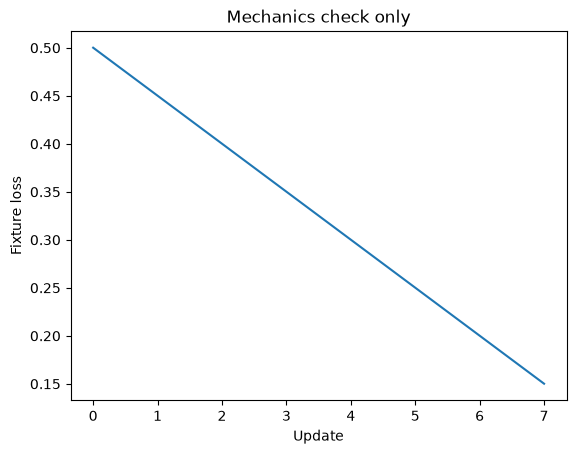

✓ cycles batches in order (works with a one-shot iterator), one row per update
✓ steps=0 returns an empty history
✓ max_grad_norm reaches every update
✓ max_seconds stops the loop early and returns the completed updates
✓ empty batches, negative steps, and a non-positive time budget are rejected


In [ ]:
from time import time as now


def train_loop(
    model: ModelT,
    batches: Iterable[Mapping[str, torch.Tensor]],
    optimizer: torch.optim.Optimizer,
    loss_fn: LossCallback[ModelT],
    *,
    steps: int,
    max_grad_norm: float | None = None,
    noise: torch.Tensor | list[torch.Tensor] | tuple[torch.Tensor, ...] | None = None,
    time: torch.Tensor | list[torch.Tensor] | tuple[torch.Tensor, ...] | None = None,
    max_seconds: float | None = None,
) -> list[dict[str, float]]:
    """Run a fixed number of updates and return the metric history."""
    batches = list(batches)

    if len(batches) == 0:
        raise ValueError("No batches provided")
    if steps < 0:
        raise ValueError("Number of steps must be nonnegative")
    if max_seconds is not None and max_seconds <= 0:
        raise ValueError("Time limit must be positive")

    start = now()
    infos = []

    for step in range(steps):
        batch = batches[step % len(batches)]
        info = optimizer_update(
            model,
            batch,
            optimizer,
            loss_fn,
            noise=noise,
            time=time,
            max_grad_norm=max_grad_norm,
        )
        infos.append(info)

        if max_seconds is not None and now() - start > max_seconds:
            break

    return infos


model = TinyACT()
opt = torch.optim.SGD(model.parameters(), lr=0.1)
history = train_loop(model, [fixture], opt, tiny_act_loss, steps=8, max_grad_norm=1.0)
assert len(history) == 8 and all("loss" in item for item in history), (
    "Return exactly one metric row per update."
)
assert history[-1]["loss"] < history[0]["loss"], (
    "Repeated updates should reduce this fixed fixture loss."
)
plt.plot([item["loss"] for item in history])
plt.xlabel("Update")
plt.ylabel("Fixture loss")
plt.title("Mechanics check only")
plt.show()

# More behaviour checks: lesson04_checks.py, next to this notebook.
from lesson04_checks import check_train_loop

check_train_loop(train_loop)

## Full experiment — build the baseline

Use the learner's ACT loss and update function with 256 real training batches and 64 fixed validation batches. The model starts with the prepared `bowl_plate` checkpoint. Save the initial model and processors, measure validation action error, and run one baseline LIBERO rollout.

In [ ]:
import json
import time
from collections.abc import Mapping, Sequence
from pathlib import Path
from uuid import uuid4

import torch
from lerobot.policies.act import ACTPolicy

from vla_lab.evaluation.demo import run_act_demo
from vla_lab.policy.act import make_act_config, make_act_processors
from vla_lab.policy.bundle import load_act_bundle, save_act_bundle
from vla_lab.teaching.interfaces import ACTPredictionModel
from vla_lab.teaching.live import load_act_batches, make_act_raw_model

TASK_ALIAS = "bowl_plate"
CHUNK_SIZE = 20
BATCH_SIZE = 8
TRAIN_BATCH_COUNT = 256
VALIDATION_BATCH_COUNT = 64
UPDATE_BUDGET = 1500
UPDATE_BLOCK = 100
WALL_LIMIT_S = 2 * 60 * 60
SAVE_RESERVE_S = 180
GPU_MEMORY_LIMIT_GB = 48
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
SEED = 17

if not torch.cuda.is_available():
    raise RuntimeError("The required full ACT training experiment needs CUDA.")
GPU_BYTES = torch.cuda.get_device_properties(0).total_memory
if GPU_BYTES > GPU_MEMORY_LIMIT_GB * 1024**3:
    torch.cuda.set_per_process_memory_fraction((GPU_MEMORY_LIMIT_GB * 1024**3) / GPU_BYTES)
DEVICE = torch.device("cuda")
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.cuda.reset_peak_memory_stats(DEVICE)
OUTPUT = WORKSPACE / ".local-data/course-runs/unit04" / uuid4().hex
OUTPUT.mkdir(parents=True, exist_ok=False)

ACT_DATA = load_act_batches(
    TASK_ALIAS,
    WORKSPACE,
    batch_size=BATCH_SIZE,
    chunk_size=CHUNK_SIZE,
    train_batches=TRAIN_BATCH_COUNT,
    validation_batches=VALIDATION_BATCH_COUNT,
    seed=SEED,
)
TRAIN_BATCHES_CPU = ACT_DATA.train
VALIDATION_BATCHES_CPU = ACT_DATA.validation
print("Frozen dataset identity:", ACT_DATA.metadata)

CONFIG = make_act_config(device=str(DEVICE), chunk_size=CHUNK_SIZE)
PREPROCESSOR, POSTPROCESSOR = make_act_processors(CONFIG, TASK_ALIAS, WORKSPACE / "configs")
POLICY = ACTPolicy(CONFIG).to(DEVICE)
MODEL = make_act_raw_model(POLICY)
OPTIMIZER = torch.optim.AdamW(
    POLICY.get_optim_params(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)


def move_batch(batch: Mapping[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    """Move only the batch used by the current update."""
    return {key: value.to(DEVICE) for key, value in batch.items()}


KL_WEIGHT = 1.0


def device_act_loss(
    model: ACTPredictionModel,
    batch: Mapping[str, torch.Tensor],
    *,
    noise: torch.Tensor | None = None,
    time: torch.Tensor | None = None,
) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
    del noise, time
    device_batch = move_batch(batch)
    prediction, (mu, logvar) = model(device_batch)
    if mu is None or logvar is None:
        raise ValueError("ACT training requires latent mean and log variance")
    action_loss = masked_action_l1(
        prediction, device_batch["action"], device_batch["action_is_pad"]
    )
    kl_loss = diagonal_gaussian_kl(mu, logvar)
    return action_loss + KL_WEIGHT * kl_loss, {"action_l1": action_loss, "kl": kl_loss}


def validation_action_l1(
    model: torch.nn.Module,
    batches: Sequence[Mapping[str, torch.Tensor]],
) -> float:
    model.eval()
    values = []
    with torch.inference_mode():
        for cpu_batch in batches:
            batch = move_batch(cpu_batch)
            prediction, _latent = model(batch)
            values.append(masked_action_l1(prediction, batch["action"], batch["action_is_pad"]))
    return float(torch.stack(values).mean().cpu())


BASELINE_BUNDLE = OUTPUT / "baseline"
save_act_bundle(
    POLICY, PREPROCESSOR, POSTPROCESSOR, BASELINE_BUNDLE, TASK_ALIAS, WORKSPACE / "configs"
)
BEFORE_VALIDATION_L1 = validation_action_l1(MODEL, VALIDATION_BATCHES_CPU)
ROLLOUT_BEFORE = run_act_demo(
    task_alias=TASK_ALIAS,
    checkpoint=BASELINE_BUNDLE,
    state_id=0,
    configs_root=WORKSPACE / "configs",
    data_root=WORKSPACE / ".local-data",
    output_dir=OUTPUT / "rollout-before",
)
print("Baseline:", {"validation_action_l1": BEFORE_VALIDATION_L1, "rollout": ROLLOUT_BEFORE})

Frozen dataset identity: {'task_alias': 'bowl_plate', 'dataset_revision': 'a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4', 'split_sha256': 'ef237195fc6ace8a78ff69fcf472362a89adb64a4ff079b5fb84724157bb82f4', 'train_episode_ids': [379, 422, 426, 431, 433, 447, 448, 451, 459, 466, 481, 483, 488, 507, 511, 513, 522, 532, 537, 549, 551, 563, 568, 582, 607, 615, 620, 621, 626, 634, 639, 642, 646, 653, 655, 670, 679, 708, 716], 'validation_episode_ids': [718, 726, 727, 749, 750, 768, 770, 801, 803, 806], 'seed': 17, 'chunk_size': 20, 'batch_size': 8, 'train_rows': 2048, 'validation_rows': 512, 'normalization_source': '/home/michal/code/vlas_tutorial/configs/data/stats/bowl_plate.json', 'device': 'cpu'}
Loading weights from local directory
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Baseline: {'validation_action_l1': 0.8865348696708679, 'rollout': {'schema_version': 1, 'policy': 'act', 'task_alias': 'bowl_plate', 'state_id': 0, 'reset_seed': 20260930, 'state_partition': 'development', '

## Full experiment — run ACT updates

Each block uses `train_loop` with the same ACT objective as the exercise. The time budget includes data setup and preserves three minutes for final saving and evaluation. The update loop checks the time budget before each update. It can finish one update that began just before the deadline. Save a checkpoint and optimizer state after every completed block.
Checkpoint blocks do not restart the data order. The next block starts at the next unused batch; the order wraps only after every selected batch has been used.


In [23]:
RUN_STARTED = time.monotonic()
DEADLINE = RUN_STARTED + WALL_LIMIT_S - SAVE_RESERVE_S
updates = 0
training_history: list[dict[str, float]] = []
LAST_BUNDLE: Path | None = None
while updates < UPDATE_BUDGET and time.monotonic() < DEADLINE:
    remaining_s = DEADLINE - time.monotonic()
    if remaining_s <= 0:
        break
    requested = min(UPDATE_BLOCK, UPDATE_BUDGET - updates)
    # Continue through all batches when a checkpoint block ends.
    batch_offset = updates % len(TRAIN_BATCHES_CPU)
    block_batches = TRAIN_BATCHES_CPU[batch_offset:] + TRAIN_BATCHES_CPU[:batch_offset]
    block_history = train_loop(
        MODEL,
        block_batches,
        OPTIMIZER,
        device_act_loss,
        steps=requested,
        max_grad_norm=1.0,
        max_seconds=remaining_s,
    )
    training_history.extend(block_history)
    updates += len(block_history)
    status = "complete" if updates == UPDATE_BUDGET else "incomplete"
    LAST_BUNDLE = OUTPUT / f"checkpoint-{updates:05d}"
    save_act_bundle(
        POLICY, PREPROCESSOR, POSTPROCESSOR, LAST_BUNDLE, TASK_ALIAS, WORKSPACE / "configs"
    )
    torch.save(OPTIMIZER.state_dict(), LAST_BUNDLE / "optimizer.pt")
    progress = {
        "status": status,
        "updates": updates,
        "update_budget": UPDATE_BUDGET,
        "seed": SEED,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "kl_weight": 1.0,
        "dataset": ACT_DATA.metadata,
        "elapsed_s": time.monotonic() - RUN_STARTED,
    }
    (LAST_BUNDLE / "training_progress.json").write_text(
        json.dumps(progress, indent=2, sort_keys=True) + "\n"
    )
    if block_history:
        print(
            f"updates={updates}/{UPDATE_BUDGET} elapsed_s={progress['elapsed_s']:.1f} loss={block_history[-1]['loss']:.5f}"
        )
    if len(block_history) < requested:
        break
TRAINING_COMPLETE = updates == UPDATE_BUDGET
if LAST_BUNDLE is None:
    raise TimeoutError(
        "No training update completed before the deadline; keep the baseline record."
    )
print({"training_complete": TRAINING_COMPLETE, "updates": updates, "checkpoint": str(LAST_BUNDLE)})

updates=100/1500 elapsed_s=391.6 loss=1.24332
updates=200/1500 elapsed_s=396.8 loss=1.01911
updates=300/1500 elapsed_s=402.0 loss=0.89398
updates=400/1500 elapsed_s=407.2 loss=0.90527
updates=500/1500 elapsed_s=412.4 loss=0.79397
updates=600/1500 elapsed_s=417.6 loss=0.80570
updates=700/1500 elapsed_s=422.8 loss=0.83138
updates=800/1500 elapsed_s=428.1 loss=0.65974
updates=900/1500 elapsed_s=433.3 loss=0.74514
updates=1000/1500 elapsed_s=438.5 loss=0.72888
updates=1100/1500 elapsed_s=443.7 loss=0.63743
updates=1200/1500 elapsed_s=448.9 loss=0.59362
updates=1300/1500 elapsed_s=454.1 loss=0.65773
updates=1400/1500 elapsed_s=459.3 loss=0.54529
updates=1500/1500 elapsed_s=464.5 loss=0.59164
{'training_complete': True, 'updates': 1500, 'checkpoint': '/home/michal/code/vlas_tutorial/.local-data/course-runs/unit04/48228ec1ce914d329ae88965c546e4e9/checkpoint-01500'}


## Full experiment — reload and evaluate

Load the last checkpoint and its saved processor pipelines. Compare the same fixed validation batches and development state with the baseline. The record keeps validation action error separate from task success. A run that reaches the time limit stays marked incomplete.

In [24]:
FINAL_POLICY, FINAL_PREPROCESSOR, FINAL_POSTPROCESSOR, FINAL_MANIFEST = load_act_bundle(LAST_BUNDLE)
FINAL_POLICY = FINAL_POLICY.to(DEVICE)
FINAL_MODEL = make_act_raw_model(FINAL_POLICY)
AFTER_VALIDATION_L1 = validation_action_l1(FINAL_MODEL, VALIDATION_BATCHES_CPU)
if not TRAINING_COMPLETE:
    print("Training stopped before the full update budget; evaluation is partial.")
AFTER_ROLLOUT = run_act_demo(
    task_alias=TASK_ALIAS,
    checkpoint=LAST_BUNDLE,
    state_id=0,
    configs_root=WORKSPACE / "configs",
    data_root=WORKSPACE / ".local-data",
    output_dir=OUTPUT / "rollout-after",
)
record = {
    "status": "complete" if TRAINING_COMPLETE else "incomplete",
    "updates": updates,
    "update_budget": UPDATE_BUDGET,
    "elapsed_s": time.monotonic() - RUN_STARTED,
    "device": str(DEVICE),
    "gpu_peak_memory_gb": torch.cuda.max_memory_allocated(DEVICE) / 1024**3,
    "dataset": ACT_DATA.metadata,
    "validation_action_l1_before": BEFORE_VALIDATION_L1,
    "validation_action_l1_after": AFTER_VALIDATION_L1,
    "validation_action_l1_after_reload": validation_action_l1(
        make_act_raw_model(FINAL_POLICY), VALIDATION_BATCHES_CPU
    ),
    "checkpoint_manifest": FINAL_MANIFEST,
    "rollout_before": ROLLOUT_BEFORE,
    "rollout_after": AFTER_ROLLOUT,
    "checkpoint": str(LAST_BUNDLE),
}
(OUTPUT / "training_record.json").write_text(json.dumps(record, indent=2, sort_keys=True) + "\n")
print(json.dumps(record, indent=2, sort_keys=True))

Loading weights from local directory
Loading weights from local directory
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
{
  "checkpoint": "/home/michal/code/vlas_tutorial/.local-data/course-runs/unit04/48228ec1ce914d329ae88965c546e4e9/checkpoint-01500",
  "checkpoint_manifest": {
    "chunk_size": 20,
    "dataset_revision": "a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4",
    "n_action_steps": 10,
    "policy": "act",
    "schema_version": 1,
    "split_sha256": "ef237195fc6ace8a78ff69fcf472362a89adb64a4ff079b5fb84724157bb82f4",
    "task_alias": "bowl_plate",
    "training_stats_sha256": {
      "action": "d2706bf63364f128125e253b20b59a1f80c590a888254b85ca662cd8261deb3a",
      "observation.state": "4bd3106c075fbd7b802d116c712e608f45e4b5418a67900b6f3de1b3cc779bc7"
    }
  },
  "dataset": {
    "batch_size": 8,
    "chunk_size": 20,
    "dataset_revision": "a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4",
    "device": "cpu",
    "normalization_source": "/home/michal/code/vlas_tutorial

## Evidence and limits

A completed record includes a real update count, separate training and validation episode identities, validation action error before and after training, a saved ACT checkpoint with its processors, a reload check, and paired simulator rollouts. A lower validation error does not prove higher task success. Simulator success on one state is one rollout, not a general claim. The dataset stores examples at 10 FPS; the environment uses one relative action per 20 Hz control step.
